In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

In [2]:
# throwing a die N_sample times and doing it N times

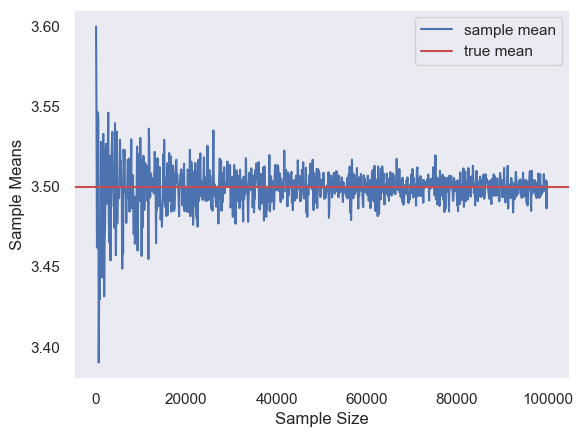

In [3]:
rvs = list(range(1, 7))
true_mean = sum(rvs)/len(rvs)


sample_sizes = np.arange(10, 100000, 100)
sample_means = []

for n in sample_sizes:
    sample_mean = np.random.choice(a=rvs, size=n).mean()
    sample_means.append(sample_mean)


plt.plot(sample_sizes, sample_means, label="sample mean")
plt.axhline(y=true_mean, color="r", label="true mean")
plt.grid()
plt.xlabel("Sample Size")
plt.ylabel("Sample Means")
plt.legend()

Population mean = 1.0, population var = 1.0


Sample size = 5
Mean of Sample means = 1.0021599306173874, Var of Sample means = 0.20183446056151008

Sample size = 50
Mean of Sample means = 1.0009532498989588, Var of Sample means = 0.020122971492186188

Sample size = 100
Mean of Sample means = 1.0017087902747355, Var of Sample means = 0.009967515388398887



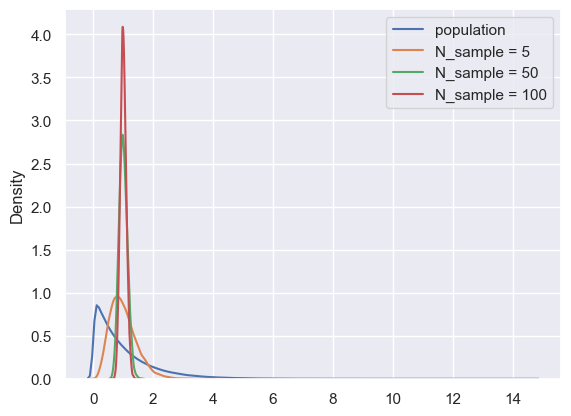

In [5]:
N_population = 1000000
N_expt = 10000
population = np.random.exponential(size=N_population)
pop_mean, pop_var = population.mean(), population.var()
print(f"Population mean = {round(pop_mean, 2)}, population var = {round(pop_var, 2)}")
print()
print()
sns.kdeplot(x=population, label="population")



sample_sizes = [5, 50, 100]
for sample_size in sample_sizes:
    sample_means = [np.random.choice(a=population, size=sample_size).mean() for _ in range(N_expt)]
    mean_of_sample_means, var_of_sample_means = np.mean(sample_means), np.var(sample_means)
    print(f"Sample size = {sample_size}")
    print(f"Mean of Sample means = {mean_of_sample_means}, Var of Sample means = {var_of_sample_means}")
    print()
    sns.kdeplot(x=sample_means, label=f"N_sample = {sample_size}")
plt.legend()

In [ ]:
# class 29

In [40]:
import pandas as pd
from sympy import *
from scipy.stats import norm, t

target = "MEDV"
df = pd.read_csv("../data/boston_housing.csv", usecols=[target])
df.head()

,MEDV
0,24.0
1,21.6
2,34.7
3,33.4
4,36.2


# Estimating population mean from a $N_{expt}$ observation

N(population) = 506
Mean = 22.532806324110677, Population variance = 84.5867235940986



N(samples) = 50
Mean of sample means = 22.552629999999997, Variance of sample means = 1.4391188471

Estimated population mean = 22.552629999999997, Estimated population variance = 71.955942355


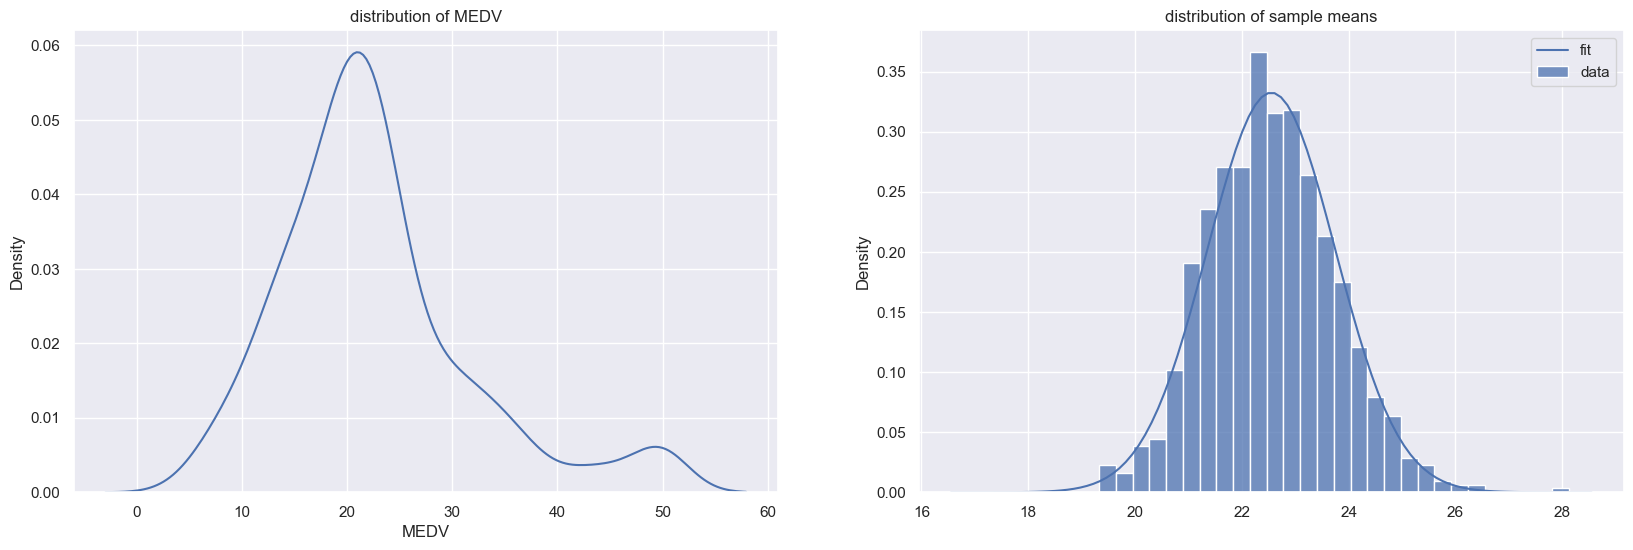

In [22]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 6))

sns.kdeplot(data=df, x=target, ax=ax[0])
ax[0].set_title(f"distribution of {target}")

mu_true, var_true = df[target].mean(), df[target].var()
print(f"N(population) = {len(df)}")
print(f"Mean = {mu_true}, Population variance = {var_true}")
print("\n\n")

N_expt, N_samples = 1000, 50
samples = [df[target].sample(N_samples, replace=False).tolist() for _ in range(N_expt)]
sample_means = [np.mean(sample) for sample in samples]

sns.histplot(x=sample_means, stat="density", ax=ax[1], label="data")

mu_hat = np.mean(sample_means)
var_hat = np.var(sample_means)

print(f"N(samples) = {N_samples}")
print(f"Mean of sample means = {mu_hat}, Variance of sample means = {var_hat}")
print()
print(f"Estimated population mean = {mu_hat}, Estimated population variance = {N_samples*var_hat}")


sig_hat = np.sqrt(var_hat)
x_ = np.linspace(mu_hat - 5*sig_hat, mu_hat + 5*sig_hat, num=100)
sns.lineplot(x=x_, y=norm.pdf(x_, loc=mu_hat, scale=sig_hat), ax=ax[1], label="fit")
ax[1].set_title("distribution of sample means")
ax[1].legend();

# Estimating population variance from a single observation

In [32]:
sample = np.array(samples[0])

sample_mean, biased_sample_var = sample.mean(), sample.var()
print(f"Sample mean = {sample_mean}, Biased sample variance = {biased_sample_var}")

unbiased_sample_var = sample.var(ddof=1) # unbiased
print(f"Unbiased sample variance = {unbiased_sample_var}")

Sample mean = 22.208, Biased sample variance = 83.19473599999999
Unbiased sample variance = 84.89258775510203


In [34]:
x = symbols("x")
f = exp(-0.5*x**2)/(sqrt(2*pi))

solve(integrate(f, (x, -x, x)) - 0.95, x)

[1.95996398454006]

In [52]:
norm.ppf(0.025)

-1.9599639845400545

In [58]:
t.ppf(0.025, df=49)

-2.0095752371292397

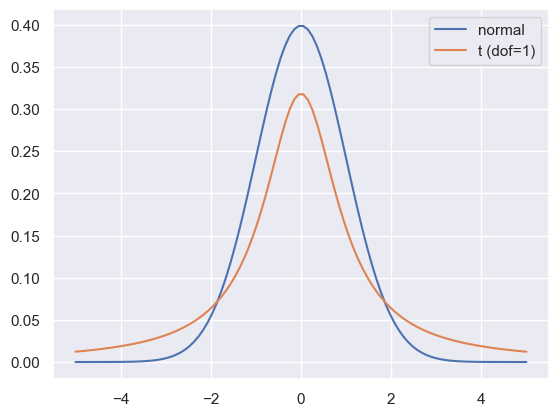

In [48]:
x = np.linspace(-5, 5, num=100)

plt.plot(x, norm.pdf(x, loc=0, scale=1), label="normal")
dof=1
plt.plot(x, t.pdf(x, loc=0, scale=1, df=dof), label=f"t (dof={dof})")
plt.legend()

In [ ]:
# Q. 1

In [65]:
z = (115-120)/(10/np.sqrt(50))
z

-3.5355339059327378

In [71]:
significance = 0.05
N = 50

print(norm.ppf(significance))
print(t.ppf(significance, df=N-1))

-1.6448536269514729
-1.6765508926168542


In [76]:
# Q. 2

In [78]:
z = (18-0)/(8/np.sqrt(50))
z

15.90990257669732

In [80]:
significance = 0.05
N = 50

print(norm.ppf(significance))


-1.6448536269514729


In [ ]:
# Q. 3

In [82]:
z = (1180-1200)/(100/np.sqrt(30))
z

-1.0954451150103321

In [86]:
significance = 0.01
N = 30

# print(norm.ppf(significance))
print(t.ppf(significance, df=N-1))

-2.4620213601503838
